In [5]:

##############################################################
###  This Notebook can do interact, see instructions below ###
##############################################################


# -*- coding: utf-8 -*-
"""
Created on Mon Jun 30 22:06:32 2025

@author: jiaxx213
"""

import torch
import torch.nn as nn
import torch.optim as optim
import pickle
import os
import sys
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split, Subset

from functions_basic import var_list, load_sourcedata, exist_split, create_split, random_new_seed, get_all_seeds
from functions_data import Data_Manager
from functions_LITT import Trainer_LITT
from functions_Events import Event_Analyzer
from functions_Path import Path_Analyzer

#method_name = "T2" # 
split_rate = 0.7
hidden_size = 16

n_batch = 32
n_epochs = 35
n_epoches_gamma = 35

#-------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU is available!")
    print(torch.cuda.get_device_name(0))
else:
    print("Warning! No GPU available, back to CPU")

#-------------------
var_dict = {s: i for i, s in enumerate(var_list)}
dim_x = len(var_list)

#'HF','IS','ARR','CA'
oc_names = ['HF','IS','ARR','AM','CA']



###### Comment Code of loading data and training ######
###### The current version is only for result display, without data loading ######

# #-------------------
# loaded_data = load_sourcedata()
# sequences = loaded_data['sequences']
# time_sequences = loaded_data['time_sequences']
# targets_dict = loaded_data['targets']
# last_days = loaded_data['last_days']
# pid_list = loaded_data['pid_list']

# oc_targets = {k: targets_dict[k] for k in oc_names}
# last_days = torch.tensor(last_days, dtype=torch.float32)

# # ---------------------
# data_manager = Data_Manager(sequences, time_sequences, oc_targets, hidden_size, n_batch, device)
# data_manager.load_full()

#trainer_LITT = Trainer_LITT(data_manager)
#trainer_LITT.loading()
#dataloader_LITT, _ = data_manager.get_DataLoader('LITT')
#trainer_LITT.run_training(n_epochs, dataloader_LITT)
#trainer_LITT.run_flipping(n_epochs, data_manager)

#event_analyzer = Event_Analyzer(data_manager, pid_list)
#event_analyzer.load_events()
#recur_dict = event_analyzer.do_analyze(log_out=False)

# slt_evts = ['metformin_1', 'insulin_1', 'sulfonylurea_1', 'glp1_recpt_1', 'sglt2_inhib_1', 'glp1_recpt_1', 'ezetimibe_1', 'fibrates_1', 'bile_acid_1', 'diuretics_1', 'diabetes_1', 'hypertension_1', 'obesity_1', 'smoking_1', 'ckd_1']
# event_analyzer.disp_3heatmap([("radiation",1)], [("anthracyclins",1)], [("targeted",1)], slt_evts)


#path_analyzer = Path_Analyzer(data_manager, pid_list)
#path_analyzer.loading()

#path_list = path_analyzer.select_path(recur_dict)
#path_analyzer.compact_path(path_list)


event_path_fname = './full_LITT_event_paths'
with open(event_path_fname, 'rb') as f:
    recur_dict = pickle.load(f)


#path_analyzer = Path_Analyzer(data_manager)
path_analyzer = Path_Analyzer()
path_analyzer.loading()
slt_keys = ['anthracyclins', 'targeted', 'radiation', 'diabetes', 'hypertension', 'obesity', 'ckd', 'metformin', 'insulin', 'sulfonylurea', 'glp1_recpt', 'sglt2_inhib', 'ezetimibe', 'fibrates', 'bile_acid', 'diuretics']

path_list = path_analyzer.select_path(recur_dict, slt_keys, 6)
#print(f"n_paths = {len(path_list)}")


from functions_Flipped import Flipping_Analyzer


#flip_analyzer = Flipping_Analyzer(data_manager, recur_dict, path_list)
flip_analyzer = Flipping_Analyzer(recur_dict, path_list)
flip_analyzer.loading()
flip_analyzer.do_analysis()



Warning! No GPU available, back to CPU
Loading full_timing from ./full_LITT_timing.pkl ...
Loading existing flipped_timing from ./full_LITT_flipped_timing.pkl ...


In [2]:
recur_dict.keys()

dict_keys(['Radia_2', 'Radia_3', 'Chemo_3', 'Targt_3', 'Radia_1', 'Chemo_2', 'Targt_1', 'Chemo_1', 'Targt_2', 'Dx_DB_2', 'Dx_DB_3', 'Dx_HT_3', 'DxSmk_1', 'Dx_DB_1', 'M_Mtf_1', 'Dx_HT_2', 'Dx_HT_1', 'Dx_Ob_1', 'Dx_HL_1', 'M_Diu_1', 'DxCKD_3', 'DxCKD_1', 'DxCKD_2', 'Dx_HL_2', 'Dx_HL_3', 'Dx_Ob_2', 'Dx_Ob_3', 'DxSmk_2', 'M_Sul_1', 'DxSmk_3', 'M_Ezt_1', 'M_Ins_1', 'M_GLP_1'])

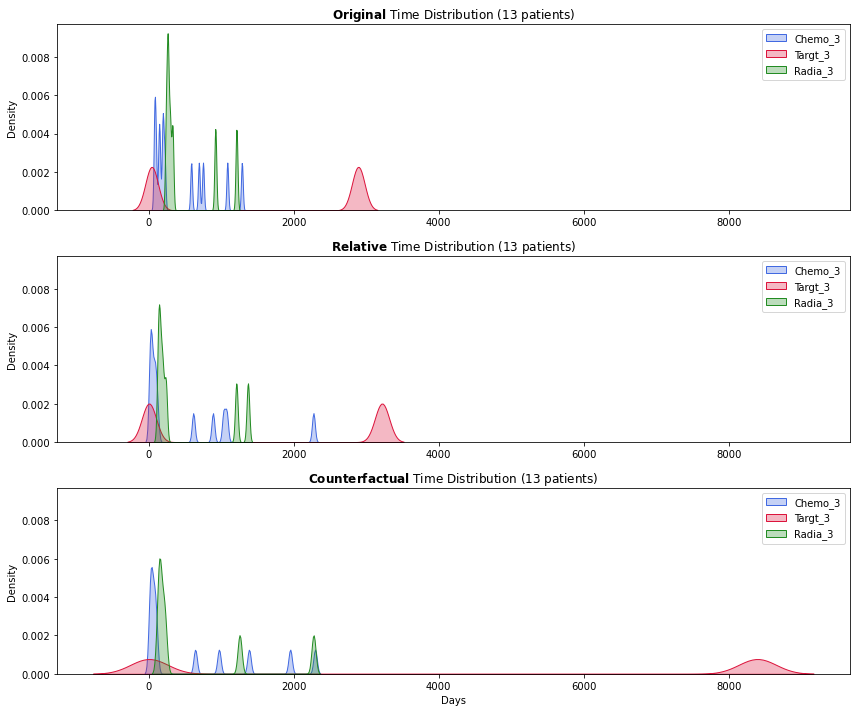

In [6]:

###### Interact Instruction ######
# The plot_compare() function displays three types of timing distributions of the selected patient cohort: 
#    1) Original Timing from data
#    2) Relative Timing (LITT-derived)
#    3) Counterfactual Timing (LITT-derived by flipping positive labels to be negative), i.e., the "what-if" counterfactual timing
# Parameters: 
#    path_id: to select cohort by specifying trajectory ID (i.e., the square-bracketed number in front of each trajectory in main_LITT_Path.ipynb outputs)
#    path_step: to select until which step of the trajectory the cohort truly present (larger step implies more narrowed cochort); -1 means the full trajectory until the last step 
#    plt_events: the three events you want to display for the comparision 
#    bw_adjust: parameter of seaborn.kdeplot() to scale the smoothing bandwidth.


path_id = 54
path_step = -1   # -1 for full path
path_info = [path_id, path_step]
plt_events = ['Chemo_3', 'Targt_3', 'Radia_3']
bw_adjust = 0.05
flip_analyzer.plot_compare(path_info, plt_events, bw_adjust)


###### To Confirm the Effectiveness of Counterfactual ######
# the significant difference between the Relavent and the Counterfactual Timing distribution provides the Counterfactual Reasining deduced by LITT
# e.g., in the displayed example, significantly Postpone (or Cancel if exceeding observation time window) the event Target_3 can majorly reduce the chance of diagnosed heart diseases for these patients



positive 13, negative 8


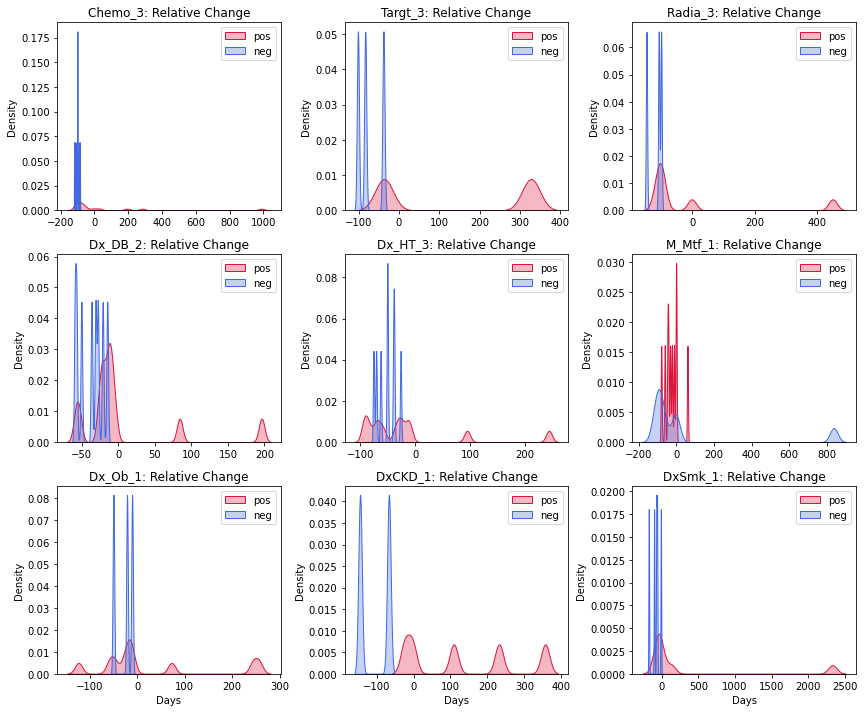

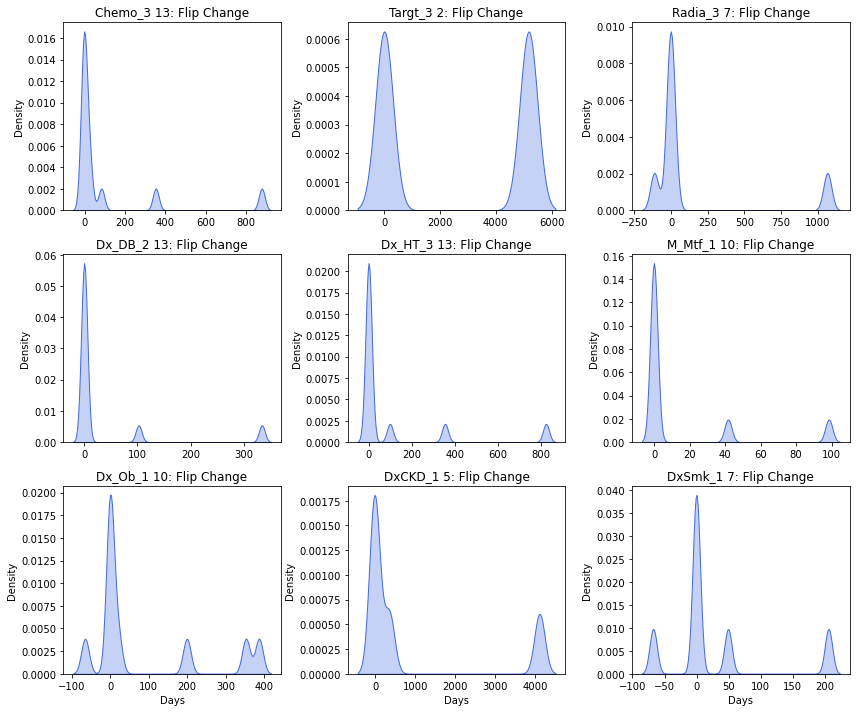

In [ ]:

###### Interact Instruction ######
# The plot_relv_changes() function displays 9 event changes from Original to Relative Timing: 
# The plot_flip_changes() function displays 9 event changes from Relative to Counterfactual Timing (positive cases only): 
# Parameters: 
#    path_info: same with above
#    slt_events: The 9 events you want to display


#slt_events = ['Chemo_1', 'Chemo_2', 'Chemo_3', 'Targt_1', 'Targt_2', 'Targt_3', 'Radia_1', 'Radia_2', 'Radia_3']
slt_events = ['Chemo_3', 'Targt_3', 'Radia_3', 'Dx_DB_2', 'Dx_HT_3', 'M_Mtf_1', 'Dx_Ob_1', 'DxCKD_1', 'DxSmk_1']



flip_analyzer.plot_relv_changes(path_info, slt_events)
flip_analyzer.plot_flip_changes(path_info, slt_events)